# 03 - Streaming analytics - a read-only PostgreSQL snapshot

**Synthetic streaming replay is a simulation, not evidence of real company churn trends.**
The producer samples/replays a static Telco dataset. Prediction volume, predicted churn
share and risk are model outputs; they are not observed business churn or accuracy.

Read the existing PostgreSQL views with the server-side **reader** role. No ML model runs
and no events are inserted. Credentials come from `backend/.env` or the process environment
and are never displayed. Export tables/figures plus a timestamped snapshot manifest.
See [setup and snapshot reproduction](../../docs/NOTEBOOKS.md).

In [1]:
from pathlib import Path
import sys, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

here = Path.cwd().resolve()
BACKEND = next((p / "backend" if (p / "backend/config.yaml").exists() else p)
               for p in [here, *here.parents]
               if (p / "backend/config.yaml").exists() or (p / "config.yaml").exists() and (p / "src/opsyntra").exists())
sys.path.insert(0, str(BACKEND / "src"))
from opsyntra.ml.notebooks import Exports, verified_partition, model_reports, validation_scores, analytics_snapshot
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=["#285b46", "#a97c35", "#587b9e", "#915780", "#718d57", "#b36154", "#5c8c89"]),
                     "svg.hashsalt": "opsyntra"})
OUT = Exports(BACKEND, "03_streaming_analytics")
print("Export directory:", OUT.directory.relative_to(BACKEND).as_posix())

Export directory: reports/notebooks/03_streaming_analytics


## A consistent, explicit scope

Use the selected engine/model and the last 24 **complete UTC hours**, excluding the current
partial hour. This aligns with the existing hourly views without counting events outside
a partial boundary bucket. Set `OPSYNTRA_NOTEBOOK_ENGINE`, `OPSYNTRA_NOTEBOOK_MODEL_VERSION`,
`OPSYNTRA_NOTEBOOK_AS_OF` (timezone-aware), and `OPSYNTRA_NOTEBOOK_HOURS` to override it.

One repeatable-read SQL transaction backs all tables. Live data can change on rerun; the
exported CSVs preserve the exact snapshot used by these figures. Compare dashboard API
values using the exact query below, not its default rolling window or another model.

In [2]:
tables, snapshot = analytics_snapshot(engine=os.getenv("OPSYNTRA_NOTEBOOK_ENGINE","sklearn"),
                      model_version=os.getenv("OPSYNTRA_NOTEBOOK_MODEL_VERSION") or None,
                      as_of=os.getenv("OPSYNTRA_NOTEBOOK_AS_OF") or None,
                      hours=int(os.getenv("OPSYNTRA_NOTEBOOK_HOURS","24")))
from urllib.parse import urlencode
snapshot["dashboard_query"]="/api/analytics/summary?"+urlencode({k:snapshot[k] for k in ["engine","model_version","start","end"] if snapshot[k] is not None})
for name,table in tables.items():OUT.table(name,table)
print("Snapshot UTC:",snapshot["snapshot_at"])
print("Scope:",{k:snapshot[k] for k in ["engine","model_version","start","end"]})
print("Matching dashboard API query:",snapshot["dashboard_query"])
display(tables["summary"])

Snapshot UTC: 2026-10-20T16:00:32.208815+00:00
Scope: {'engine': 'sklearn', 'model_version': 'd9a13b4cf6839ed4', 'start': '2026-10-19T16:00:00+00:00', 'end': '2026-10-20T16:00:00+00:00'}
Matching dashboard API query: /api/analytics/summary?engine=sklearn&model_version=d9a13b4cf6839ed4&start=2026-10-19T16%3A00%3A00%2B00%3A00&end=2026-10-20T16%3A00%3A00%2B00%3A00


,prediction_volume,unique_events,unique_customers,predicted_churn_share,mean_risk,matched_raw_predictions
0,10112,10112,7043,0.409217,0.266146,10112


## Hourly event-time activity

Volume counts logical prediction IDs, not Kafka deliveries. Unique customers must be
computed over the whole selection, not summed across hourly distinct counts. Empty hour
volume is zero; absent risk/churn share stays missing rather than becoming a false zero.

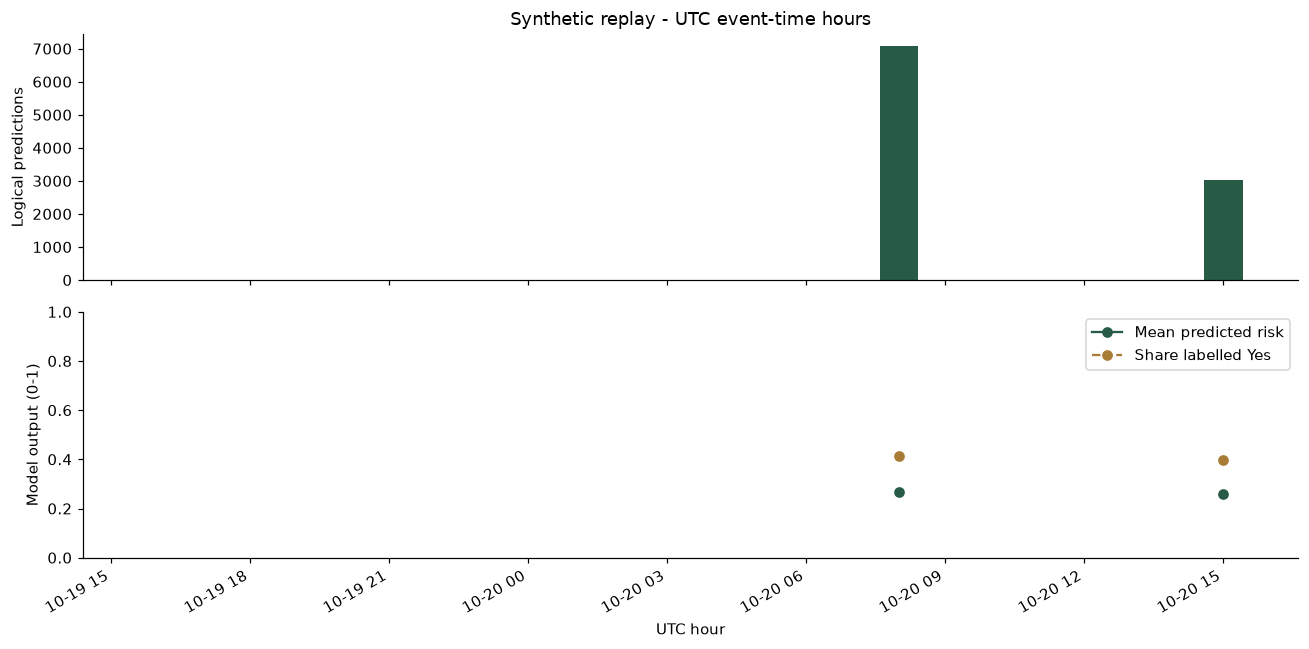

In [3]:
hours=pd.date_range(snapshot["start"],snapshot["end"],freq="h",inclusive="left")
hourly=tables["hourly"].copy()
hourly["bucket_start"]=pd.to_datetime(hourly.bucket_start,utc=True)
hourly=hourly.set_index("bucket_start").reindex(hours)
hourly["prediction_volume"]=hourly.prediction_volume.fillna(0).astype(int)
assert int(hourly.prediction_volume.sum())==int(tables["summary"].iloc[0].prediction_volume)
OUT.table("hourly_gap_filled",hourly.rename_axis("bucket_start").reset_index())
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True)
axes[0].bar(hours,hourly.prediction_volume,width=.035);axes[0].set(ylabel="Logical predictions",title="Synthetic replay - UTC event-time hours")
axes[1].plot(hours,hourly.mean_risk,marker="o",label="Mean predicted risk")
axes[1].plot(hours,hourly.predicted_churn_share,marker="o",label="Share labelled Yes",linestyle="--")
axes[1].set(ylabel="Model output (0-1)",xlabel="UTC hour",ylim=(0,1));axes[1].legend()
fig.autofmt_xdate();fig.tight_layout();OUT.figure("hourly_activity",fig);plt.show()

## Risk, original-event contract and payment segments

Features join predictions to raw records by **event_id**, never by the customer's latest
profile. Unmatched predictions remain in totals. Models and engines remain separate.
Segment mean risk is weighted by its logical prediction count when combining hourly groups.

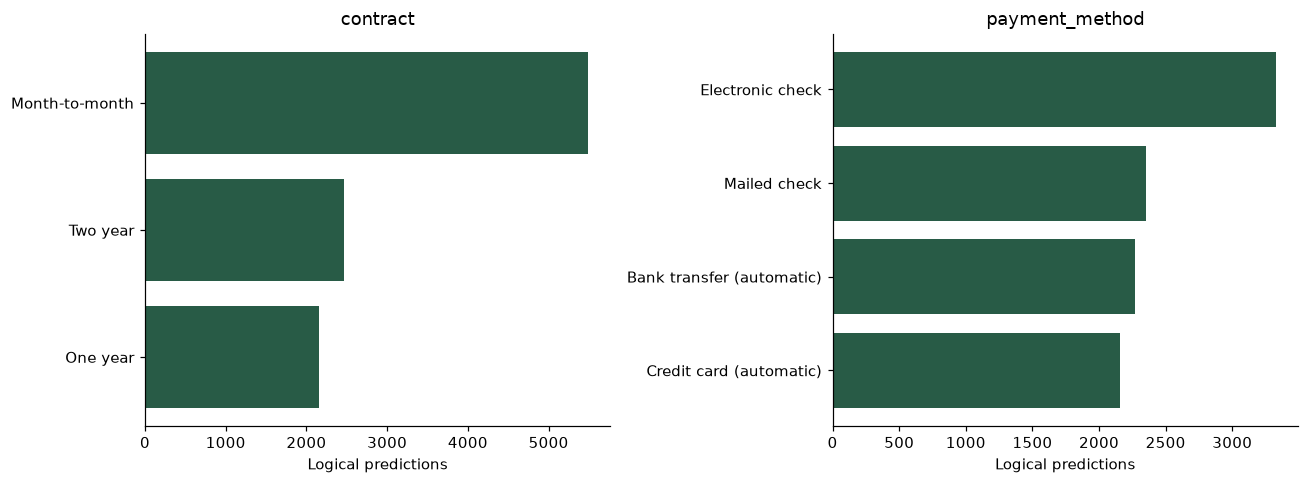

,risk_band,prediction_volume
0,0–30%,6205
1,30–70%,3378
2,70–100%,529


,prediction_id,event_id,customer_id,engine,model_version,churn_probability,prediction,event_ts,processed_ts,ingested_at,contract,payment_method
0,20ecc3b05f0e594c58d73e023225fd45209b9480fce090...,13212170-0059-5dcc-bef9-9fd209272cda,4537-CIBHB,sklearn,d9a13b4cf6839ed4,0.043255,No,2026-10-20 15:29:34.217579+00:00,2026-10-20 15:30:15.341868+00:00,2026-10-20 15:36:50.310911+00:00,One year,Mailed check
1,789503369855fe201890f36a5a81c24794bb44af81375d...,8d39ea36-dc9f-57ea-8e3d-e3ad63c179ae,4231-LZUYM,sklearn,d9a13b4cf6839ed4,0.006763,No,2026-10-20 15:29:31.313164+00:00,2026-10-20 15:30:15.341860+00:00,2026-10-20 15:36:50.307229+00:00,Two year,Bank transfer (automatic)
2,32f5df54f4cb29cf44f05b6a453e49820e2598dacf06df...,76a560c3-1d27-5440-8134-c022625a9e41,6695-FRVEC,sklearn,d9a13b4cf6839ed4,0.028517,No,2026-10-20 15:29:49.445246+00:00,2026-10-20 15:30:15.341856+00:00,2026-10-20 15:36:50.304377+00:00,Two year,Bank transfer (automatic)
3,7dfed2576f014e4bdd6099398779f1cb0c39c34757c865...,bb756ef5-392c-5456-9b1a-60db84bf3daf,0774-IFUVM,sklearn,d9a13b4cf6839ed4,0.194047,No,2026-10-20 15:29:46.669808+00:00,2026-10-20 15:30:15.341848+00:00,2026-10-20 15:36:50.300370+00:00,Month-to-month,Bank transfer (automatic)
4,f5196385b9138c4d8e324668f15416dc7850064c39c0de...,d620ae80-4677-527a-93d1-9acf326abb86,4667-QONEA,sklearn,d9a13b4cf6839ed4,0.068630,No,2026-10-20 15:29:42.749112+00:00,2026-10-20 15:30:15.341831+00:00,2026-10-20 15:36:50.297719+00:00,One year,Credit card (automatic)
5,4bd5c09001ddcae4f26fdc6ec19d43e03e1063c04c2864...,21c3baf9-f0cf-575f-b2b1-4db5c11e5937,5248-KWLAR,sklearn,d9a13b4cf6839ed4,0.017987,No,2026-10-20 15:29:49.235882+00:00,2026-10-20 15:30:15.341813+00:00,2026-10-20 15:36:50.295298+00:00,Two year,Electronic check
6,59e93ca655f1849d8b9f47a3db7bdef503e215f703c9d7...,5b79f478-cdbc-5e05-8fd7-9fea8eedd711,4273-MBHYA,sklearn,d9a13b4cf6839ed4,0.721446,Yes,2026-10-20 15:29:48.486556+00:00,2026-10-20 15:30:15.341809+00:00,2026-10-20 15:36:50.292569+00:00,Month-to-month,Electronic check
7,a505d30f230468a988bcde12e9f9f456d4813c5d742ccc...,7650d800-6a01-5f28-a5aa-28b7cdbe5d3a,8741-LQOBK,sklearn,d9a13b4cf6839ed4,0.105085,No,2026-10-20 15:30:00.551388+00:00,2026-10-20 15:30:15.341804+00:00,2026-10-20 15:36:50.289795+00:00,Month-to-month,Bank transfer (automatic)
8,0bf9220b575bee53832548ad91795453cd8809a0f8b564...,425b9bd2-9bbe-5524-90fb-ad7516fb5dd0,2819-GWENI,sklearn,d9a13b4cf6839ed4,0.014552,No,2026-10-20 15:29:32.299882+00:00,2026-10-20 15:30:14.717906+00:00,2026-10-20 15:36:50.286876+00:00,One year,Mailed check
9,fea28c3232fd5236650e5fb806b8ea73cdb0f627b3829a...,d41fe765-151f-5b38-ae2c-4d96299b826e,2725-KXXWT,sklearn,d9a13b4cf6839ed4,0.763203,Yes,2026-10-20 15:30:03.922033+00:00,2026-10-20 15:30:14.717902+00:00,2026-10-20 15:36:50.284104+00:00,Month-to-month,Electronic check


In [4]:
segments=tables["segments"]
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,field in zip(axes,["contract","payment_method"]):
    group=segments.assign(label=segments[field].fillna("Profile not received")).groupby("label").prediction_volume.sum().sort_values()
    if len(group):ax.barh(group.index,group.values)
    else:ax.text(.5,.5,"No predictions in this scope",ha="center",transform=ax.transAxes)
    ax.set(title=field,xlabel="Logical predictions")
    OUT.table(field+"_segments",group.rename_axis("label").reset_index(name="prediction_volume"))
fig.tight_layout();OUT.figure("original_event_segments",fig);plt.show()
display(tables["risk_distribution"])
display(tables["recent"])

## Late events, physical duplicates and rejected records

A late event here means ingestion more than **one hour after event time**, an explicit
operational threshold, not a claim that a customer changed behaviour. Negative latency is
reported as clock skew. Ordinary SQL views recompute event-time buckets when late records
arrive; no counter is incremented per delivery.

Physical-delivery provenance can show multiple offsets for one logical prediction. The
extra deliveries are not extra customer requests. This table cannot count duplicates that
the upstream inference ledger suppressed before publishing. Legitimate repeated customer
events have different event IDs and remain separate. Quarantine counts cover all engines
by ingestion time; they cannot safely be attributed to the selected model.

In [5]:
display(tables["deliveries"])
display(tables["late_summary"])
display(tables["late_events"])
display(tables["quarantine"])
n=int(tables["summary"].iloc[0].prediction_volume)
assert int(tables["segments"].prediction_volume.sum())==n
assert int(tables["risk_distribution"].prediction_volume.sum())==n
assert int(tables["deliveries"].iloc[0].logical_predictions)==n
OUT.finish(**snapshot,logical_predictions=n,read_only=True,fitted_models=0,
           checks={"hourly_sum_matches_summary":True,"segment_sum_matches_summary":True,"risk_sum_matches_summary":True})
print("PASS: hourly/segment/risk totals match the scoped logical SQL count.")
print("Simulation only: these charts do not establish real company churn trends or accuracy.")

,logical_predictions,physical_deliveries,repeated_deliveries,predictions_without_delivery_provenance
0,10112,10124,12,0


,over_one_hour,clock_skew_events
0,7085,0


,prediction_id,event_id,event_ts,ingested_at,event_to_ingestion_seconds
0,83755907fc3bf8bb4b9449ff6abae5d0166dccd8d32ac5...,f4375fc6-365c-5051-acb6-3e523d4cf03b,2026-10-20 08:16:35.286751+00:00,2026-10-20 15:23:12.856226+00:00,25597.569475
1,11694bc561b9594caa298db4fc032566c319d35a3b25ed...,3eb0d321-d544-51f6-a408-af6f8d0944a7,2026-10-20 08:16:47.169437+00:00,2026-10-20 15:23:12.842547+00:00,25585.673110
2,989b9252ce7dcea14834fe502293eb314306b82cfd0c7a...,ab49c0dc-5e4b-5300-b87e-9d0d3da9d16c,2026-10-20 08:16:50.300012+00:00,2026-10-20 15:23:12.835192+00:00,25582.535180
3,a7e083a1b3b0ed2085f017723b0743d53f1d0ee5630fc1...,0cb89c56-025c-5e4f-977e-416af4d9b9b1,2026-10-20 08:16:50.918323+00:00,2026-10-20 15:23:12.846089+00:00,25581.927766
4,c09c98086918c868824873dc7e9d07cfdf04c9f05c1d66...,aab24d2b-054b-5b2e-b4a3-8c0f19bf1841,2026-10-20 08:16:56.037402+00:00,2026-10-20 15:23:12.830760+00:00,25576.793358
5,86947b5b1767adb29a958d8728ae0958c37827d6502e79...,3bb87025-3d5b-5bb0-bec6-93a843ed41cd,2026-10-20 08:16:59.466747+00:00,2026-10-20 15:23:12.865062+00:00,25573.398315
6,2936ea073367567d76587447d7e26702a03b3a458238cd...,3a89019f-cff1-5b3f-a138-c4917164adf6,2026-10-20 08:17:05.998931+00:00,2026-10-20 15:23:12.852715+00:00,25566.853784
7,9180c6cd16aafcc41e723cbe255705515e4c87818d3809...,0dee1003-c556-55c8-a6d1-95b792d74dab,2026-10-20 08:17:18.932174+00:00,2026-10-20 15:23:12.825892+00:00,25553.893718
8,47a01f44624f6849caf9c6c3b796bfa58529e96c3cc2d0...,4ffc792d-1be5-58ce-b0ba-cc83139413d3,2026-10-20 08:17:19.253097+00:00,2026-10-20 15:23:12.838603+00:00,25553.585506
9,a124e58159be515cc394de58932e40cc92c991de344b40...,2ca84b87-e7db-5456-a0bc-9fbdcd87e3f6,2026-10-20 08:17:26.338154+00:00,2026-10-20 15:23:12.821008+00:00,25546.482854


,event_kind,error_type,records
0,raw,event_conflict,2
1,raw,invalid_record,12


PASS: hourly/segment/risk totals match the scoped logical SQL count.
Simulation only: these charts do not establish real company churn trends or accuracy.
